# BÀI TẬP 5: TRỰC QUAN HÓA DỮ LIỆU CHUỖI THỜI GIAN

### Mục tiêu bài thực hành:
1. **Line chart:** Vẽ toàn bộ chuỗi thời gian **AirPassengers** (144 quan sát, 01/1949 – 12/1960).
2. **Rolling statistics:** Vẽ **rolling mean** và **rolling std** với cửa sổ `window = 12`.
3. **Seasonal plot:** Vẽ biểu đồ mùa vụ theo tháng (mỗi năm một đường).
4. **Heatmap seasonality:** Vẽ heatmap **tháng × năm**.
5. **Kết luận:** Xu hướng chung, các mùa vụ nổi bật và các điểm bất thường (nếu có).


In [1]:
# Ô 1: Import các thư viện cần thiết

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm
from matplotlib.colors import Normalize
from statsmodels.tsa.seasonal import STL

# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Đã import thành công các thư viện cần thiết.")


Đã import thành công các thư viện cần thiết.


In [2]:
# Ô 2: Tải dữ liệu AirPassengers
data_path = "../../data/raw/AirPassengers.csv"

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    df["Month"] = pd.to_datetime(df["Month"])
    ts = pd.Series(df["Passengers"].values,
                   index=pd.DatetimeIndex(df["Month"], freq="MS"),
                   name="Passengers")
else:
    # Nạp dự phòng nếu chưa có file csv trong data/raw
    air_values = [
        112,118,132,129,121,135,148,148,136,119,104,118,
        115,126,141,135,125,149,170,170,158,133,114,140,
        145,150,178,163,172,178,199,199,184,162,146,166,
        171,180,193,181,183,218,230,242,209,191,172,194,
        196,196,236,235,229,243,264,272,237,211,180,201,
        204,188,235,227,234,264,302,293,259,229,203,229,
        242,233,267,269,270,315,364,347,312,274,237,278,
        284,277,317,313,318,374,413,405,355,306,271,306,
        315,301,356,348,355,422,465,467,404,347,305,336,
        340,318,362,348,363,435,491,505,404,359,310,337,
        360,342,406,396,420,472,548,559,463,407,362,405,
        417,391,419,461,472,535,622,606,508,461,390,432
    ]
    dates = pd.date_range(start="1949-01-01", periods=len(air_values), freq="MS")
    ts = pd.Series(air_values, index=dates, name="Passengers")
    print("Đã nạp dữ liệu trực tiếp.")

print("Số lượng quan sát:", len(ts))
print("Khoảng thời gian: từ", ts.index[0].strftime("%Y-%m"), "đến", ts.index[-1].strftime("%Y-%m"))
print("Tần suất:", ts.index.freqstr, "(theo tháng)")
print("Số giá trị thiếu:", ts.isna().sum())


Đã nạp dữ liệu trực tiếp.
Số lượng quan sát: 144
Khoảng thời gian: từ 1949-01 đến 1960-12
Tần suất: MS (theo tháng)
Số giá trị thiếu: 0


## 1. Line chart toàn bộ chuỗi

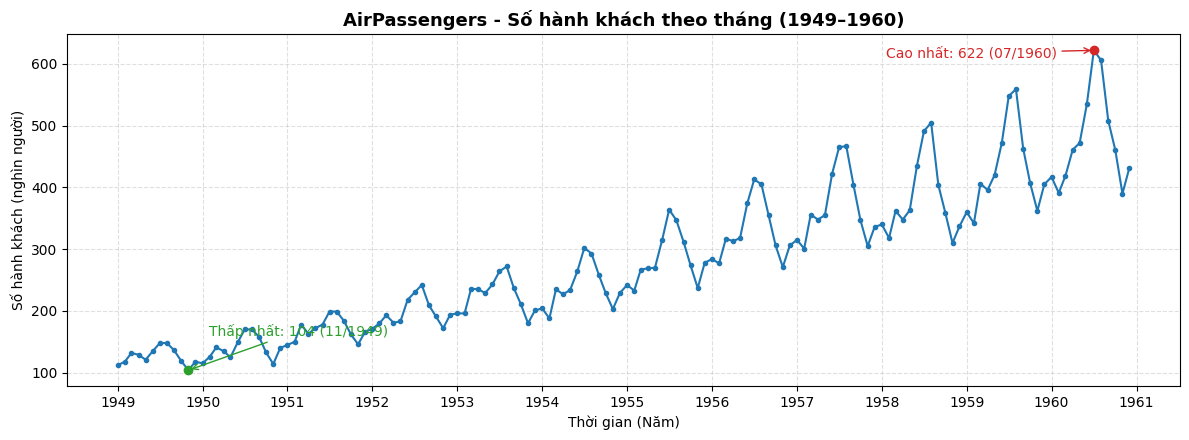

In [3]:
# Ô 3: Vẽ line chart toàn bộ chuỗi

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(ts.index, ts.values, color="#1f77b4", linewidth=1.5, marker="o", markersize=3)

# Đánh dấu giá trị lớn nhất và nhỏ nhất
t_max, v_max = ts.idxmax(), ts.max()
t_min, v_min = ts.idxmin(), ts.min()
ax.scatter([t_max], [v_max], color="#d62728", zorder=5)
ax.annotate(f"Cao nhất: {v_max} ({t_max:%m/%Y})", xy=(t_max, v_max),
            xytext=(-150, -5), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#d62728"), color="#d62728")
ax.scatter([t_min], [v_min], color="#2ca02c", zorder=5)
ax.annotate(f"Thấp nhất: {v_min} ({t_min:%m/%Y})", xy=(t_min, v_min),
            xytext=(15, 25), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#2ca02c"), color="#2ca02c")

ax.set_title("AirPassengers - Số hành khách theo tháng (1949–1960)", fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel("Số hành khách (nghìn người)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## 2. Rolling mean và rolling std (window = 12)

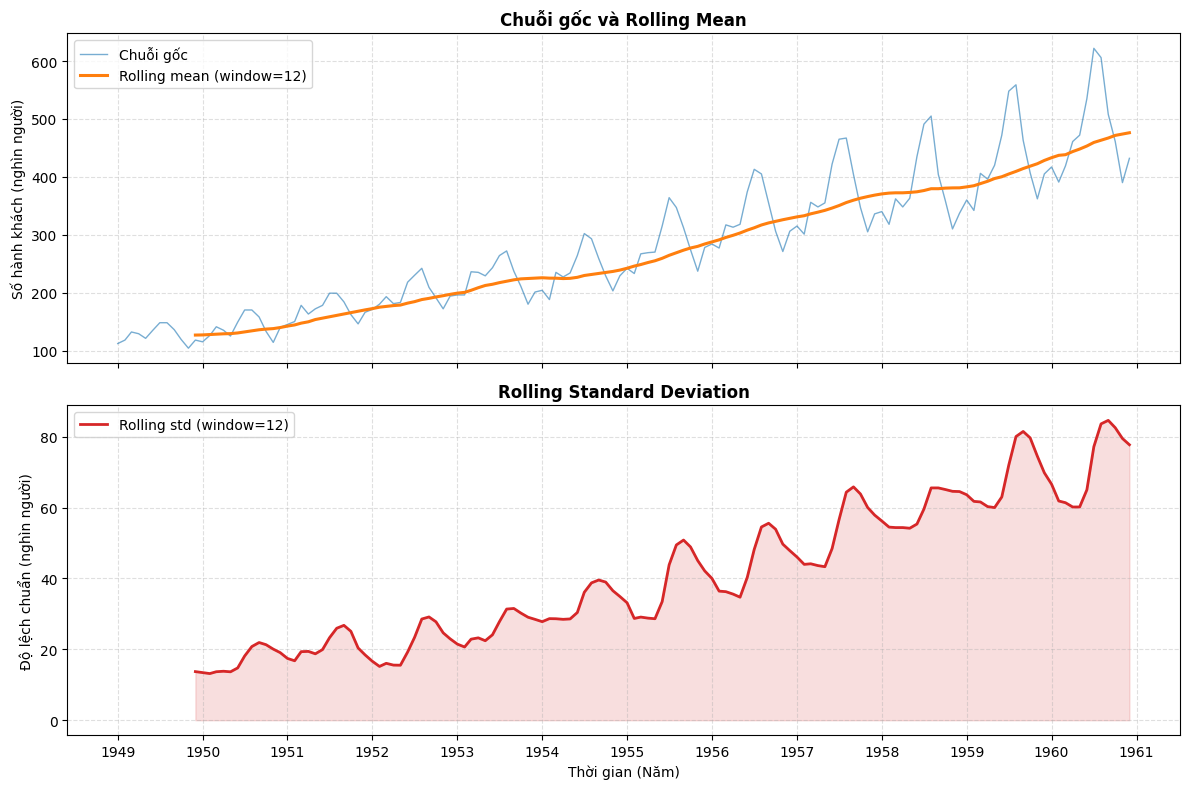

11 quan sát đầu tiên không có giá trị rolling (chưa đủ cửa sổ).
Rolling mean: 126.7 (12/1949) -> 476.2 (12/1960)
Rolling std : 13.7 (12/1949) -> 77.7 (12/1960)
Hệ số tương quan giữa rolling mean và rolling std: 0.959
Hệ số biến thiên (std/mean): trung bình 0.142, nhỏ nhất 0.087, lớn nhất 0.197


In [4]:
# Ô 4: Tính và vẽ rolling mean, rolling std với window = 12

WINDOW = 12
roll_mean = ts.rolling(window=WINDOW).mean()
roll_std = ts.rolling(window=WINDOW).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Biểu đồ 1: chuỗi gốc và rolling mean
axes[0].plot(ts.index, ts.values, color="#1f77b4", linewidth=1.0, alpha=0.6, label="Chuỗi gốc")
axes[0].plot(roll_mean.index, roll_mean.values, color="#ff7f0e", linewidth=2.2,
             label=f"Rolling mean (window={WINDOW})")
axes[0].set_title("Chuỗi gốc và Rolling Mean", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left")

# Biểu đồ 2: rolling std
axes[1].plot(roll_std.index, roll_std.values, color="#d62728", linewidth=2.0,
             label=f"Rolling std (window={WINDOW})")
axes[1].fill_between(roll_std.index, roll_std.values, alpha=0.15, color="#d62728")
axes[1].set_title("Rolling Standard Deviation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm)")
axes[1].set_ylabel("Độ lệch chuẩn (nghìn người)")
axes[1].legend(loc="upper left")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Thống kê tóm tắt
valid = pd.DataFrame({"mean": roll_mean, "std": roll_std}).dropna()
cv = valid["std"] / valid["mean"]
print(f"{WINDOW - 1} quan sát đầu tiên không có giá trị rolling (chưa đủ cửa sổ).")
print(f"Rolling mean: {valid['mean'].iloc[0]:.1f} ({valid.index[0]:%m/%Y}) -> {valid['mean'].iloc[-1]:.1f} ({valid.index[-1]:%m/%Y})")
print(f"Rolling std : {valid['std'].iloc[0]:.1f} ({valid.index[0]:%m/%Y}) -> {valid['std'].iloc[-1]:.1f} ({valid.index[-1]:%m/%Y})")
print(f"Hệ số tương quan giữa rolling mean và rolling std: {valid['mean'].corr(valid['std']):.3f}")
print(f"Hệ số biến thiên (std/mean): trung bình {cv.mean():.3f}, nhỏ nhất {cv.min():.3f}, lớn nhất {cv.max():.3f}")


## 3. Seasonal plot theo tháng

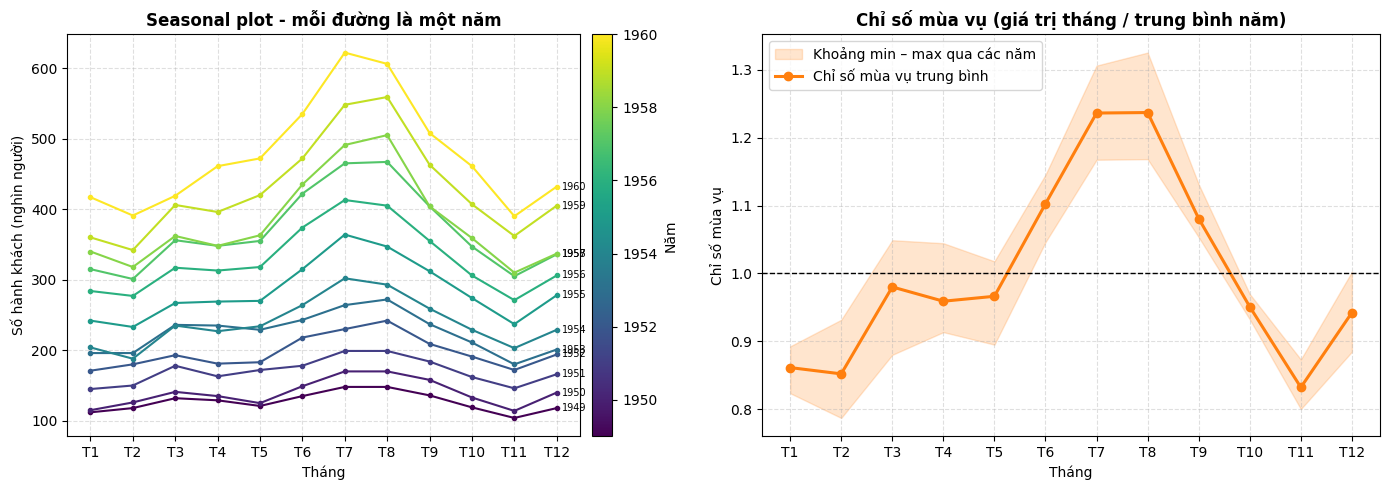

Chỉ số mùa vụ trung bình theo tháng:


Month,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12
Chỉ số mùa vụ,0.861,0.852,0.98,0.959,0.966,1.103,1.236,1.237,1.081,0.951,0.832,0.942



Số năm có đỉnh ở từng tháng: {7: 7, 8: 5}
Số năm có đáy ở từng tháng : {1: 2, 2: 4, 11: 6}


In [5]:
# Ô 5: Chuẩn bị bảng tháng × năm và vẽ seasonal plot

table = (
    ts.to_frame("Passengers")
      .assign(Year=ts.index.year, Month=ts.index.month)
      .pivot(index="Month", columns="Year", values="Passengers")
)
month_labels = [f"T{m}" for m in range(1, 13)]
years = table.columns.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: mỗi năm một đường
cmap = cm.viridis
norm = Normalize(vmin=min(years), vmax=max(years))
for y in years:
    axes[0].plot(table.index, table[y], marker="o", markersize=3, linewidth=1.5, color=cmap(norm(y)))
    axes[0].annotate(str(y), xy=(12, table.loc[12, y]), xytext=(4, 0),
                     textcoords="offset points", fontsize=7, va="center")
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axes[0], label="Năm", pad=0.02)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_labels)
axes[0].set_title("Seasonal plot - mỗi đường là một năm", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tháng")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Biểu đồ 2: chỉ số mùa vụ (giá trị tháng / trung bình năm) để loại bỏ ảnh hưởng của xu hướng
seasonal_ratio = table / table.mean(axis=0)
si_mean = seasonal_ratio.mean(axis=1)
axes[1].fill_between(table.index, seasonal_ratio.min(axis=1), seasonal_ratio.max(axis=1),
                     alpha=0.2, color="#ff7f0e", label="Khoảng min – max qua các năm")
axes[1].plot(table.index, si_mean, color="#ff7f0e", marker="o", linewidth=2.2, label="Chỉ số mùa vụ trung bình")
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_labels)
axes[1].set_title("Chỉ số mùa vụ (giá trị tháng / trung bình năm)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tháng")
axes[1].set_ylabel("Chỉ số mùa vụ")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("Chỉ số mùa vụ trung bình theo tháng:")
display(si_mean.round(3).rename("Chỉ số mùa vụ").to_frame().T.rename(columns=dict(zip(range(1, 13), month_labels))))

peak = table.idxmax(axis=0)
trough = table.idxmin(axis=0)
print("\nSố năm có đỉnh ở từng tháng:", peak.value_counts().sort_index().to_dict())
print("Số năm có đáy ở từng tháng :", trough.value_counts().sort_index().to_dict())


## 4. Heatmap seasonality (tháng × năm)

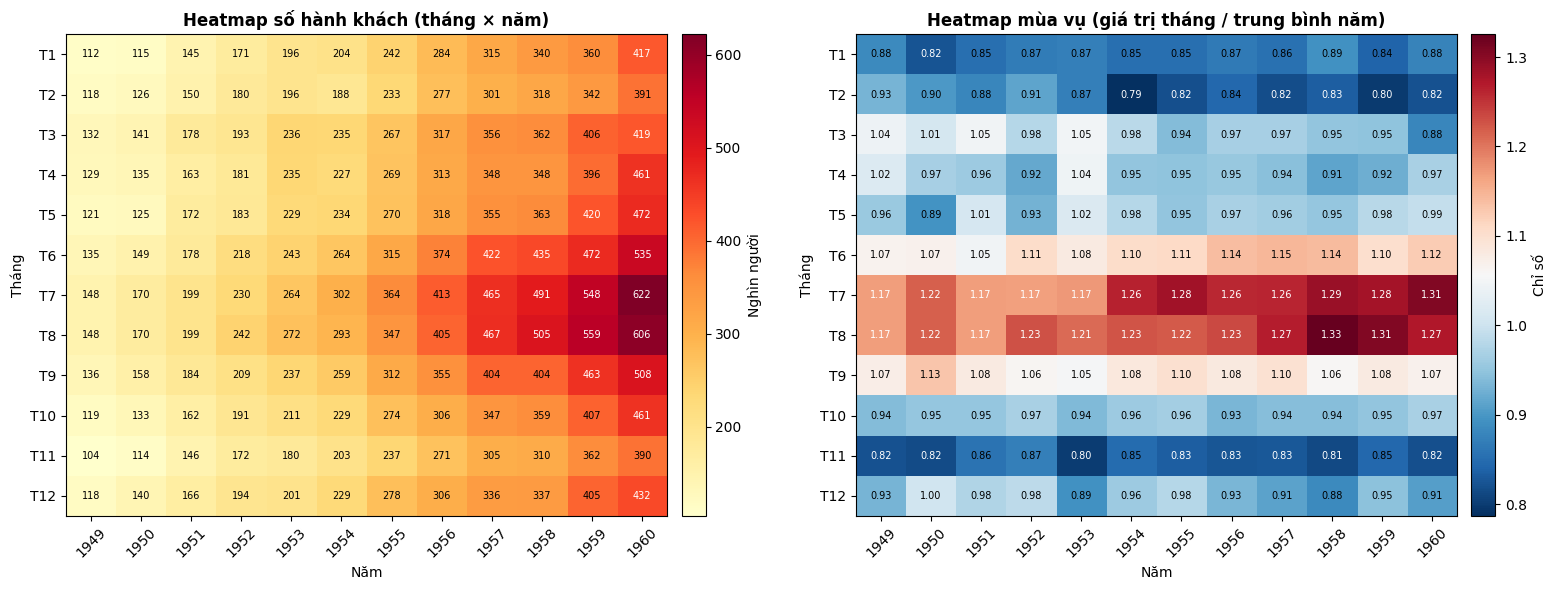

In [6]:
# Ô 6: Heatmap tháng × năm (giá trị gốc và giá trị đã chuẩn hóa theo trung bình năm)

def ve_heatmap(ax, data, title, cmap_name, fmt, cbar_label, diverging=False):
    im = ax.imshow(data.values, aspect="auto", cmap=cmap_name)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=45)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(month_labels)
    ax.set_xlabel("Năm")
    ax.set_ylabel("Tháng")
    ax.set_title(title, fontsize=12, fontweight="bold")
    # Ghi giá trị lên từng ô, đổi màu chữ theo độ đậm của ô
    vmin, vmax = np.nanmin(data.values), np.nanmax(data.values)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data.values[i, j]
            if diverging:
                # Thang phân kỳ: ô đậm ở cả hai đầu (xa mức 1) dùng chữ trắng
                dark = abs(val - 1) / max(abs(vmin - 1), abs(vmax - 1)) > 0.5
            else:
                dark = (val - vmin) / (vmax - vmin) > 0.6
            ax.text(j, i, format(val, fmt), ha="center", va="center", fontsize=7,
                    color="white" if dark else "black")
    plt.colorbar(im, ax=ax, label=cbar_label, pad=0.02)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ve_heatmap(axes[0], table, "Heatmap số hành khách (tháng × năm)", "YlOrRd", ".0f", "Nghìn người")
ve_heatmap(axes[1], seasonal_ratio, "Heatmap mùa vụ (giá trị tháng / trung bình năm)", "RdBu_r", ".2f", "Chỉ số", diverging=True)

plt.tight_layout()
plt.show()


## 5. Số liệu hỗ trợ kết luận

In [7]:
# Ô 7: Tổng hợp số liệu để rút ra kết luận

# (a) Xu hướng: trung bình theo năm và tốc độ tăng
annual = ts.groupby(ts.index.year).agg(["mean", "std", "min", "max"]).round(1)
annual["Tăng so với năm trước (%)"] = (annual["mean"].pct_change() * 100).round(1)
print("(a) Thống kê theo năm:")
display(annual)
cagr = (annual["mean"].iloc[-1] / annual["mean"].iloc[0]) ** (1 / (len(annual) - 1)) - 1
print(f"Trung bình năm tăng {annual['mean'].iloc[-1] / annual['mean'].iloc[0]:.2f} lần, tốc độ tăng bình quân ~{cagr * 100:.1f}%/năm")

# (b) Biên độ mùa vụ: chênh lệch giữa tháng 7 và tháng 11 (đỉnh và đáy điển hình)
gap = (table.loc[7] - table.loc[11])
ratio = (table.loc[7] / table.loc[11])
print("\n(b) Chênh lệch tuyệt đối T7 - T11 từng năm (nghìn người):")
print(gap.to_dict())
print(f"Tỷ lệ T7/T11: {ratio.iloc[0]:.2f} (1949) -> {ratio.iloc[-1]:.2f} (1960)")

# (c) Bất thường: phần dư STL trên thang log, đánh dấu |z| > 3
log_resid = STL(np.log(ts), period=12, robust=True).fit().resid
z = (log_resid - log_resid.mean()) / log_resid.std()
print("\n(c) Các tháng có phần dư STL (thang log) lệch quá 3 độ lệch chuẩn:")
display(pd.DataFrame({"Giá trị": ts[z.abs() > 3], "z-score": z[z.abs() > 3].round(2)}))

# (d) Biến động theo tháng lớn nhất
mom = ts.pct_change() * 100
print("(d) 3 tháng giảm mạnh nhất so với tháng trước (%):")
print(mom.nsmallest(3).round(1).to_string())


(a) Thống kê theo năm:


,mean,std,min,max,Tăng so với năm trước (%)
1949,126.7,13.7,104,148,NaN
1950,139.7,19.1,114,170,10.3
1951,170.2,18.4,145,199,21.8
1952,197.0,23.0,171,242,15.7
1953,225.0,28.5,180,272,14.2
1954,238.9,34.9,188,302,6.2
1955,284.0,42.1,233,364,18.9
1956,328.2,47.9,271,413,15.6
1957,368.4,57.9,301,467,12.2
1958,381.0,64.5,310,505,3.4


Trung bình năm tăng 3.76 lần, tốc độ tăng bình quân ~12.8%/năm

(b) Chênh lệch tuyệt đối T7 - T11 từng năm (nghìn người):
{1949: 44, 1950: 56, 1951: 53, 1952: 58, 1953: 84, 1954: 99, 1955: 127, 1956: 142, 1957: 160, 1958: 181, 1959: 186, 1960: 232}
Tỷ lệ T7/T11: 1.42 (1949) -> 1.59 (1960)

(c) Các tháng có phần dư STL (thang log) lệch quá 3 độ lệch chuẩn:


,Giá trị,z-score
1951-05-01,172,3.28
1953-03-01,236,3.05
1953-04-01,235,4.35
1953-05-01,229,3.32
1954-02-01,188,-4.28


(d) 3 tháng giảm mạnh nhất so với tháng trước (%):
1958-09-01   -20.0
1959-09-01   -17.2
1960-09-01   -16.2
Freq: 12MS


## 6. KẾT LUẬN

**1. Xu hướng chung (Trend)**
- Lượng hành khách có xu hướng **tăng mạnh và liên tục** trong cả giai đoạn 1949–1960: trung bình năm tăng từ khoảng **127 nghìn** (1949) lên khoảng **476 nghìn** (1960), gấp khoảng 3,8 lần, tương ứng tốc độ tăng bình quân khoảng 12,8%/năm.
- Rolling mean (window=12) đi lên gần như đều, không có giai đoạn suy giảm kéo dài. Tăng trưởng chậm lại rõ nhất ở năm 1954 (+6,2%) và 1958 (+3,4%).
- Rolling std cũng tăng từ khoảng 14 lên khoảng 78 và có tương quan rất cao với rolling mean (≈ 0,96): chuỗi **không dừng** cả về trung bình lẫn phương sai, độ biến động tăng theo quy mô.

**2. Mùa vụ nổi bật (Seasonality)**
- Chu kỳ **12 tháng** lặp lại ổn định ở mọi năm: đỉnh vào **tháng 7–8** (chỉ số mùa vụ ≈ 1,24, tức cao hơn trung bình năm khoảng 24%; tháng 7 là đỉnh ở 7/12 năm, tháng 8 ở 5/12 năm).
- Đáy rơi vào **tháng 11** (chỉ số ≈ 0,83), kế đến là **tháng 2 và tháng 1** (≈ 0,85–0,86). Tháng 6 và tháng 9 là hai tháng "vai" của mùa cao điểm; tháng 12 hồi nhẹ so với tháng 11.
- Biên độ mùa vụ **tăng dần theo thời gian**: chênh lệch T7 – T11 tăng từ 44 nghìn (1949) lên 232 nghìn (1960), trong khi tỷ lệ T7/T11 chỉ dao động trong khoảng 1,3–1,6. Đây là mùa vụ dạng **nhân (multiplicative)**, phù hợp với kết quả ở Bài tập 3. Heatmap chuẩn hóa cho thấy cùng một dải màu đậm ở tháng 6–9 và dải màu nhạt ở tháng 11–2 lặp lại ở mọi năm.

**3. Bất thường (Anomaly)**
- Không có outlier cực đoan: các điểm cao nhất (T7/1960 = 622) và thấp nhất (T11/1949 = 104) đều phù hợp với xu hướng và mùa vụ.
- Có một số điểm lệch nhẹ so với quy luật chung (phần dư STL trên thang log vượt 3 độ lệch chuẩn): **tháng 5/1951** và **mùa xuân 1953** (tháng 3–5) cao hơn mức mùa vụ thông thường; **tháng 2/1954** (188) thấp hơn cùng kỳ năm trước (196), là mức giảm so với cùng kỳ rõ nhất trong chuỗi.
- **Năm 1958** tăng trưởng chậm (+3,4%): các tháng 4 và 9/1958 bằng đúng mức cùng kỳ 1957 (348 và 404). Mức giảm tháng 9 so với tháng 8 (từ khoảng -7% đến -20%, mức giảm sâu hơn ở các năm về sau) là quy luật mùa vụ lặp lại ở mọi năm, không phải bất thường riêng của 1958.
- Biên độ dao động ngày càng lớn ở cuối chuỗi (rolling std tăng) là hệ quả của quy mô tăng, không phải dấu hiệu dữ liệu lỗi.

**4. Hàm ý cho mô hình hóa**
Chuỗi có xu hướng tăng, mùa vụ chu kỳ 12 và phương sai tăng theo mức, nên trước khi dự báo cần biến đổi (ví dụ lấy log) và lấy sai phân (thường và/hoặc mùa vụ) để chuỗi dừng hơn.
